# PDF·이미지 질의응답

이전 노트북(`1. Multi-Vector RAG 파이프라인 구축.ipynb`)에서 구축한 `travel_guide_pages` 인덱스를 이용해 실전 질의응답을 진행합니다.

- **PDF QA**: 검색된 페이지 이미지 + 질문 → VLM 답변 (페이지 번호 인용)
- **이미지 QA**: 검색된 여러 이미지로 비교 질의
- **Hybrid Search**: 텍스트 검색과 이미지(요약) 검색을 결합하는 방법


In [1]:
import chromadb
import fitz
import numpy as np

from rag_utils import ask_vlm, embed_text, show

client = chromadb.PersistentClient(path="./chroma_db")
collection = client.get_collection("travel_guide_pages")
print(f"불러온 페이지 수: {collection.count()}")


불러온 페이지 수: 10


In [2]:
# 이전 노트북에서 metadata에 image_path를 저장해두었기 때문에
# 커널을 새로 시작해도 Document Store를 그대로 복원할 수 있음
all_docs = collection.get(include=["metadatas"])
document_store = {
    doc_id: meta for doc_id, meta in zip(all_docs["ids"], all_docs["metadatas"])
}


## 1. PDF QA - 페이지 이미지 기반 질의응답
검색된 페이지 이미지와 질문을 함께 VLM에 전달하고, 답변에 페이지 번호를 인용하도록 프롬프트를 설계합니다.


In [3]:
def ask_pdf(question, k=3):
    query_embedding = embed_text(question)
    results = collection.query(query_embeddings=[query_embedding], n_results=k)

    doc_ids = results["ids"][0]
    image_paths = [document_store[doc_id]["image_path"] for doc_id in doc_ids]
    pages = [document_store[doc_id]["page"] for doc_id in doc_ids]

    prompt = (
        f"아래는 관광 가이드북에서 검색된 관련 페이지 {len(image_paths)}장이야. "
        f"각 페이지 번호(0부터 시작하는 순서: {pages})를 인용하며 질문에 답해줘.\n"
        f"문서에 없는 내용이면 '해당 정보 없음'이라고 답해.\n\n"
        f"질문: {question}"
    )

    answer = ask_vlm(prompt, image_paths)
    return answer, doc_ids, image_paths, pages


answer, doc_ids, image_paths, pages = ask_pdf(
    "휠체어를 이용할 수 있는 관광지를 알려주고, 몇 페이지에 있는지도 알려줘."
)
print(answer)


휠체어를 이용할 수 있는 관광지는 다음과 같습니다:

1. 서울한방진흥센터 - 페이지 5
2. 청라호수공원 - 페이지 13
3. 국립중앙박물관 - 페이지 3

각 관광지는 휠체어 이용이 가능하다고 명시되어 있습니다.


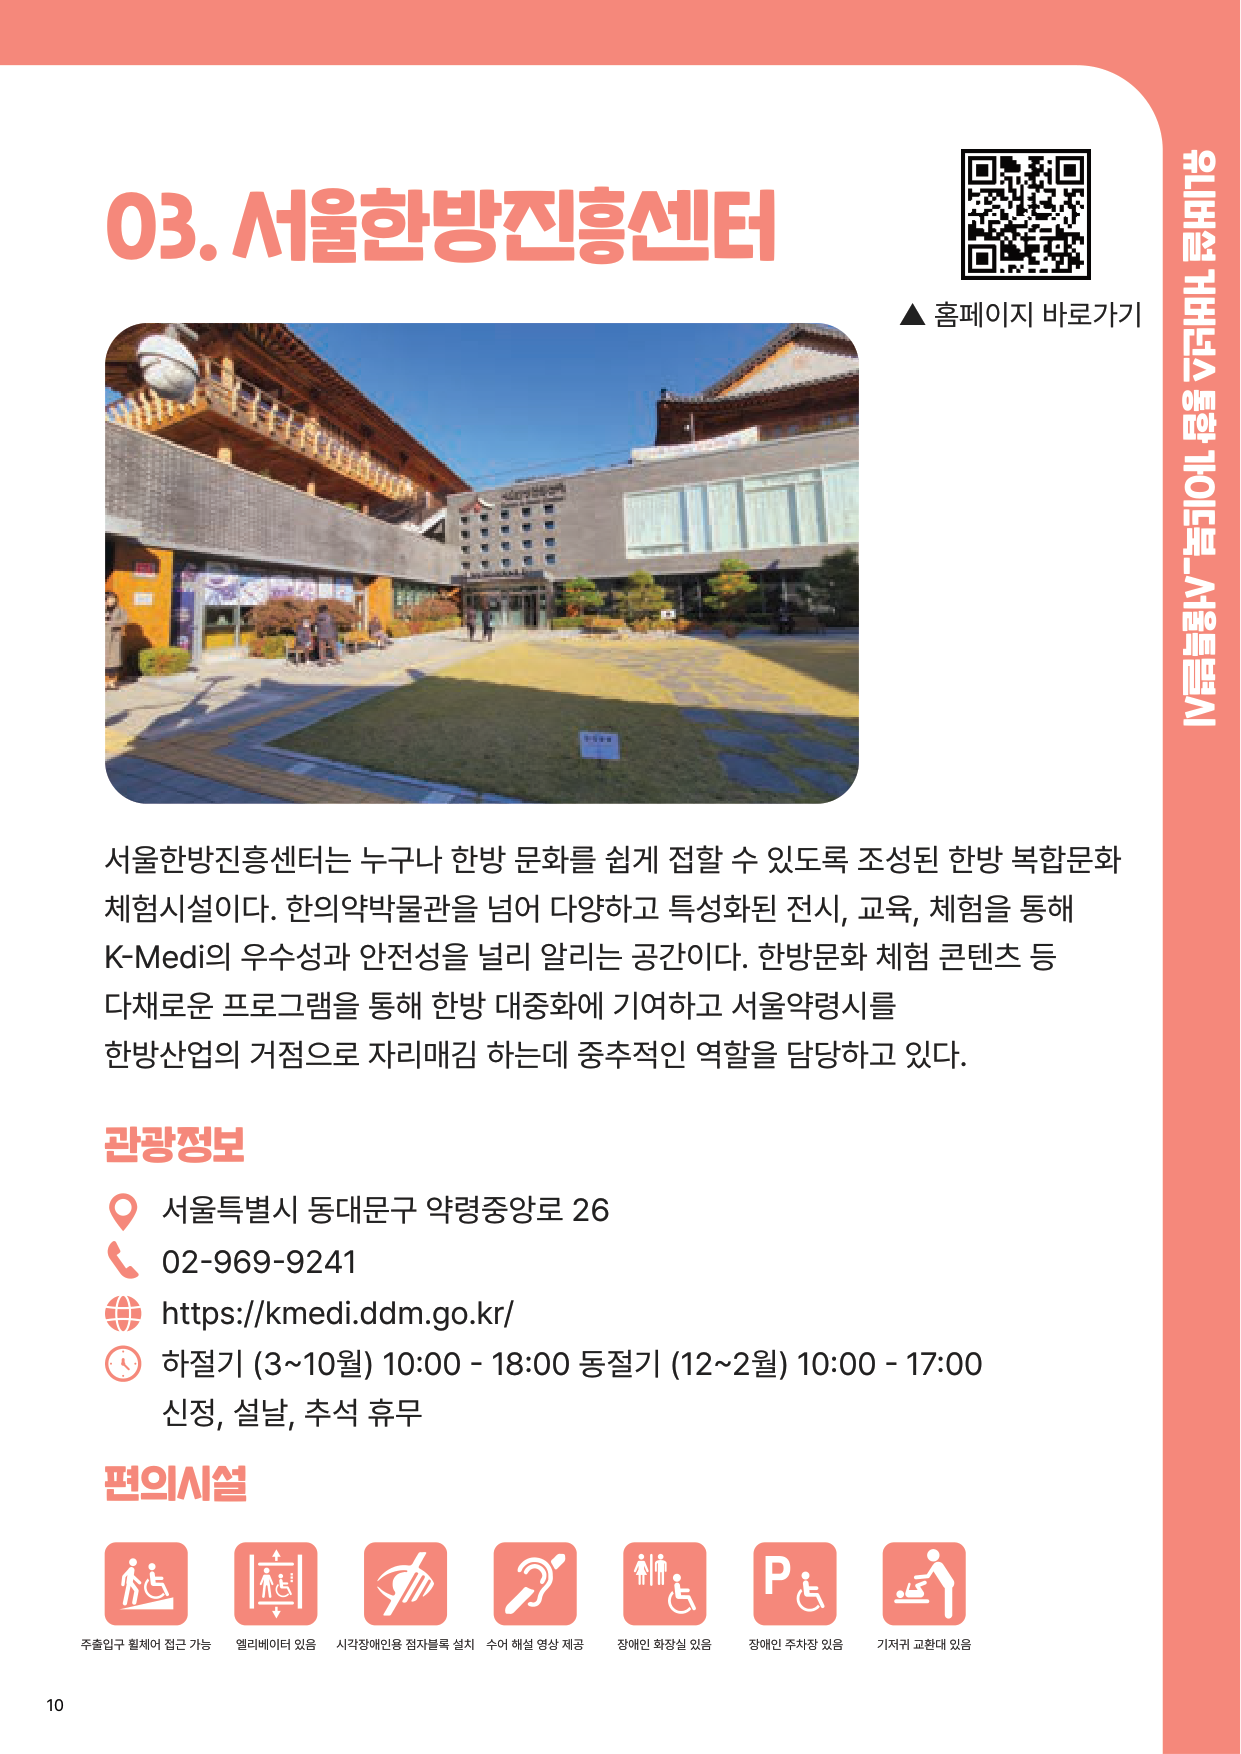

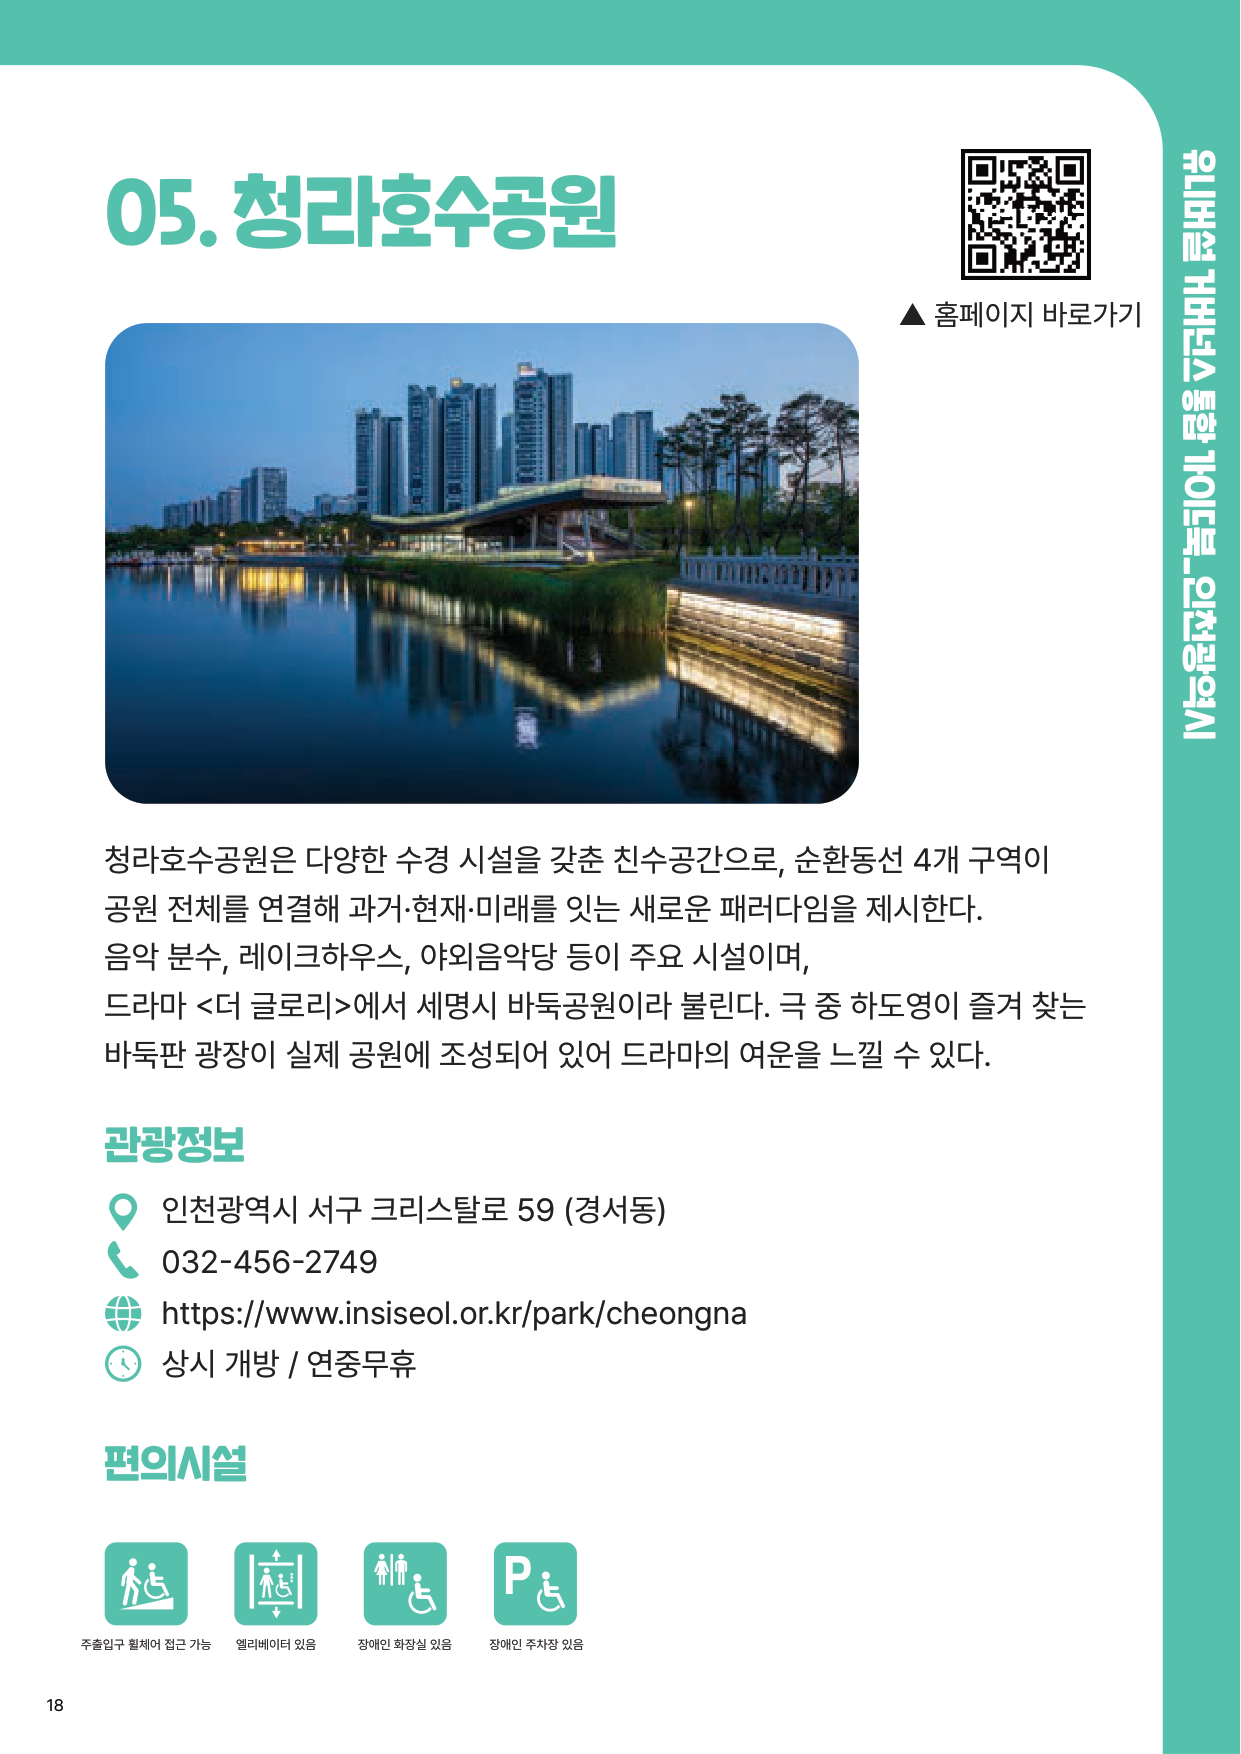

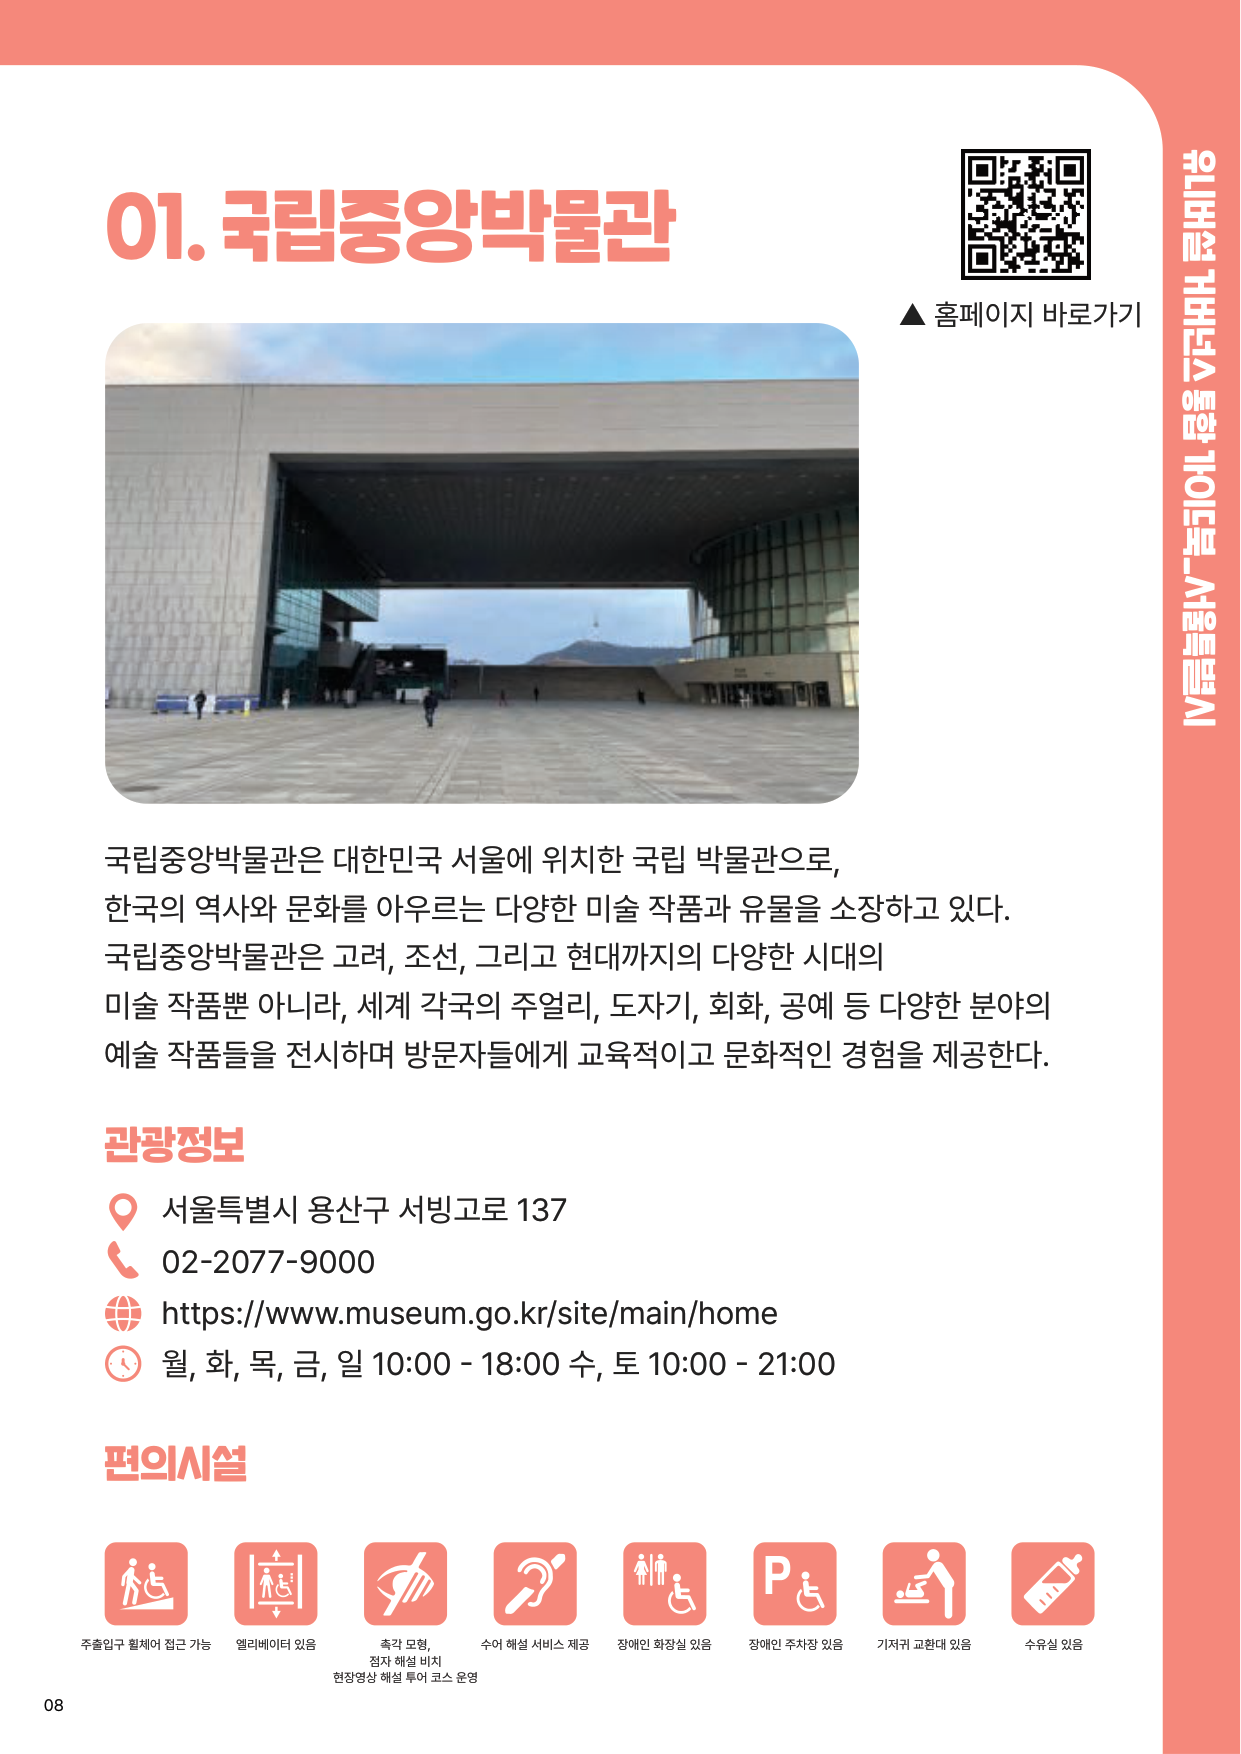

In [4]:
# 실제로 어떤 페이지가 검색되어 답변에 사용되었는지 눈으로 확인
for image_path in image_paths:
    show(image_path)


## 2. 이미지 QA - 비교 질의
검색된 이미지 여러 장을 함께 VLM에 전달하면 이미지 간 비교 질문에도 답할 수 있습니다.


In [5]:
compare_question = (
    "위에서 검색된 관광지 이미지들 중에서 아이와 함께 방문하기 가장 좋은 곳은 어디야? "
    "이유도 함께 설명해줘."
)
compare_answer = ask_vlm(compare_question, image_paths)
print(compare_answer)


아이와 함께 방문하기 가장 좋은 곳은 **청라호수공원**입니다.

### 이유:
1. **자연 친화적 환경**: 청라호수공원은 다양한 수경 시설과 넓은 공간이 있어 아이들이 자연 속에서 뛰어놀기 좋습니다. 물가에서의 활동은 아이들에게 즐거운 경험이 될 수 있습니다.

2. **다양한 시설**: 음악 분수, 레이크하우스와 같은 다양한 시설이 있어 가족 단위 방문객들이 즐길 수 있는 요소가 많습니다. 아이들이 놀 수 있는 공간이 마련되어 있어 부모님도 편안하게 시간을 보낼 수 있습니다.

3. **문화 체험**: 드라마 촬영지로도 유명한 이곳은 아이들에게 흥미로운 이야기를 제공할 수 있어, 자연과 문화 체험을 동시에 할 수 있는 기회를 제공합니다.

이러한 점들로 인해 청라호수공원은 아이와 함께 방문하기에 적합한 장소입니다.


## 3. Hybrid Search - 텍스트 검색 + 이미지(요약) 검색 결합
- 순수 텍스트 질문과 시각적 질문이 섞인 상황에 대응하기 위해, PDF **원문 텍스트 임베딩**과 페이지 **이미지 요약 임베딩**을 함께 사용해봅니다.
- 결합 방식(가중합): `score = α · text_score + (1-α) · image_score`


In [6]:
# Vector Store에는 '상세' 페이지만 색인되어 있으므로(1번 노트북 참고),
# 이미지 요약 임베딩을 먼저 페이지 순서에 맞춰 정렬해 실제 페이지 번호 목록을 구한다
all_with_emb = collection.get(include=["embeddings", "documents", "metadatas"])
order = sorted(
    range(len(all_with_emb["ids"])), key=lambda i: all_with_emb["metadatas"][i]["page"]
)
pages = [all_with_emb["metadatas"][i]["page"] for i in order]
image_embeddings = np.array([all_with_emb["embeddings"][i] for i in order])


# 결과를 숫자만이 아니라 눈으로도 확인할 수 있도록, 요약 텍스트에서 장소명을 뽑아둔다
def extract_place(summary):
    for line in summary.splitlines():
        if line.startswith("장소명:"):
            return line.split(":", 1)[1].strip()
    return "(장소명 정보 없음)"


summaries = [all_with_emb["documents"][i] for i in order]
place_names = [extract_place(summary) for summary in summaries]


In [7]:
# PDF 원문 텍스트를 이미지 임베딩과 동일한 페이지 집합·순서로 추출해 별도로 임베딩
# (개요/목차 페이지는 Vector Store에서 제외됐으므로 원문 텍스트도 같은 페이지만 사용해야 shape가 맞는다)
raw_doc = fitz.open("./data/korea_travel_guide_book.pdf")
raw_texts = [raw_doc[page].get_text() or "(텍스트 없음)" for page in pages]

text_embeddings = np.array([embed_text(text) for text in raw_texts])


In [8]:
def cosine_sim(matrix, vector):
    matrix = matrix / np.linalg.norm(matrix, axis=-1, keepdims=True)
    vector = vector / np.linalg.norm(vector)
    return matrix @ vector


def hybrid_search(query, alpha=0.5, k=3):
    query_embedding = np.array(embed_text(query))

    text_scores = cosine_sim(text_embeddings, query_embedding)
    image_scores = cosine_sim(image_embeddings, query_embedding)
    combined = alpha * text_scores + (1 - alpha) * image_scores

    top_k = np.argsort(-combined)[:k]
    return [
        (
            int(pages[p]),
            place_names[p],
            float(combined[p]),
            float(text_scores[p]),
            float(image_scores[p]),
        )
        for p in top_k
    ]


for page, place, score, text_score, image_score in hybrid_search("전망대에 엘리베이터가 있는 곳은?"):
    print(f"page={page} [{place}] combined={score:.4f} (text={text_score:.4f}, image={image_score:.4f})")


page=4 [불암산 힐링타운] combined=0.3036 (text=0.3389, image=0.2682)
page=13 [청라호수공원] combined=0.2794 (text=0.3352, image=0.2237)
page=12 [옥토끼우주센터] combined=0.2584 (text=0.3064, image=0.2105)


In [9]:
compare_query = "점자 안내나 수어 해설이 있는 곳은?"

for alpha, label in [
    (1.0, "텍스트 검색만 (alpha=1.0)"),
    (0.0, "이미지 요약 검색만 (alpha=0.0)"),
    (0.5, "하이브리드 결합 (alpha=0.5)"),
]:
    print(f"[{label}]")
    for page, place, score, text_score, image_score in hybrid_search(compare_query, alpha=alpha):
        print(f"  page={page} [{place}] combined={score:.4f} (text={text_score:.4f}, image={image_score:.4f})")
    print()


[텍스트 검색만 (alpha=1.0)]
  page=5 [서울한방진흥센터] combined=0.3969 (text=0.3969, image=0.2706)
  page=13 [청라호수공원] combined=0.3606 (text=0.3606, image=0.3059)
  page=4 [불암산 힐링타운] combined=0.3359 (text=0.3359, image=0.2823)

[이미지 요약 검색만 (alpha=0.0)]
  page=13 [청라호수공원] combined=0.3059 (text=0.3606, image=0.3059)
  page=9 [국립세계문자박물관] combined=0.2950 (text=0.3294, image=0.2950)
  page=4 [불암산 힐링타운] combined=0.2823 (text=0.3359, image=0.2823)

[하이브리드 결합 (alpha=0.5)]
  page=5 [서울한방진흥센터] combined=0.3338 (text=0.3969, image=0.2707)
  page=13 [청라호수공원] combined=0.3333 (text=0.3606, image=0.3059)
  page=9 [국립세계문자박물관] combined=0.3121 (text=0.3293, image=0.2950)



**결과 해석**: `alpha=1.0`(텍스트만)은 점자·수어 해설을 실제로 제공하는 **서울한방진흥센터(page 5)**를 1위로 정확히 찾아낸다. 반면 `alpha=0.0`(이미지 요약만)은 이 정보가 요약에 없다 보니 관련 없는 **청라호수공원(page 13)**을 1위로 잘못 고른다. `alpha=0.5`(하이브리드)는 텍스트 신호 덕분에 정답을 1위로 유지하면서도, 두 순위가 얼마나 팽팽하게 경합하는지 점수 차이로 확인할 수 있다.

→ 이미지 요약은 검색 속도·비용 면에서 유리하지만 요약 포맷이 담지 못한 세부 정보를 놓친다. 원문 텍스트를 함께 인덱싱하면 이런 손실을 보완할 수 있다는 것이 Hybrid Search의 핵심 가치다.
